# Understanding the en-route weather advisory data

This dataset contains archived convective weather advisories (Significant Meteorological Information, or SIGMETs) from the Iowa Environmental Mesonet (IEM) GIS archive in KML format. Each advisory describes an active severe convective weather area with a geographic polygon, an active UTC time window, regional identifiers, and storm text details such as maximum cloud-top altitude.

In this notebook, we inspect the raw KML placemarks and focus on the main parsed fields for domestic advisories: `sigmet_id`, `issue`, `expire`, the polygon bounding box (`west`, `south`, `east`, `north`), and `top_fl` (maximum convective cloud top in flight levels). In the modeling pipeline, each domestic flight's great-circle path is buffered into a 50 NM route corridor and checked against advisories that are active at scheduled departure to count overlapping convective advisories, flag blocked corridors, and record the highest cloud top along the route.

In [1]:
from pathlib import Path
from collections import Counter
import re
import sys
from xml.etree import ElementTree

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Show every column and keep the full text in tables.
pd.set_option('display.max_columns', None, 'display.max_rows', None, 'display.max_colwidth', None)

root = Path.cwd().resolve()
if not (root / 'config.json').is_file():
    root = root.parent
if not (root / 'config.json').is_file():
    raise FileNotFoundError('Run from the project root or notebooks directory.')
sys.path.insert(0, str(root))

from scripts.common.config import load_config, project_path
from scripts.enroute_weather import clean_sigmets

_, _, config = load_config(root)
enroute_dir = project_path(root, config['datasets']['sigmets']['bronze_directory'])
kml_files = sorted(enroute_dir.glob('*.kml'))
if not kml_files:
    raise FileNotFoundError('No local en-route advisory KML files were found.')

## Sample of raw advisory placemarks

In [2]:
raw_samples = []
first_root = ElementTree.parse(kml_files[0]).getroot()
for item in first_root.findall('.//{*}Placemark')[:5]:
    attrs = {node.attrib.get('name'): (node.text or '').strip() for node in item.findall('.//{*}SimpleData')}
    raw_samples.append({
        'LABEL': attrs.get('LABEL'),
        'TYPE': attrs.get('TYPE'),
        'ISSUE': attrs.get('ISSUE'),
        'EXPIRE': attrs.get('EXPIRE'),
        'PROD_ID': attrs.get('PROD_ID'),
        'polygons': len(item.findall('.//{*}Polygon')),
        'TEXT_preview': (attrs.get('TEXT', '')[:120] + '...') if len(attrs.get('TEXT', '')) > 120 else attrs.get('TEXT', ''),
    })
pd.DataFrame(raw_samples)

,LABEL,TYPE,ISSUE,EXPIRE,PROD_ID,polygons,TEXT_preview
0,GOLF 4,C,2023-12-30T00:20:00Z,2023-12-30T04:20:00Z,202312300020-KKCI-WSPN07-SIGP0G,1,806 \nWSPN07 KKCI 300020\nSIGP0G\nKZAK SIGMET GOLF 4 VALID 300020/300420 KKCI-\nOAKLAND OCEANIC FIR FRQ TS OBS AT 0020Z WI N...
1,1E,C,2023-12-30T00:55:00Z,2023-12-30T02:55:00Z,202312300055-KKCI-WSUS31-SIGE,1,CONVECTIVE SIGMET 1E\nVALID UNTIL 0255Z\nVA\n10NNE RIC\nISOL EMBD TS D30 MOV FROM 24020KT. TOPS TO FL250.
2,2E,C,2023-12-30T01:55:00Z,2023-12-30T03:55:00Z,202312300155-KKCI-WSUS31-SIGE,1,CONVECTIVE SIGMET 2E\nVALID UNTIL 0355Z\nVA\n30ENE RIC\nISOL EMBD TS D30 MOV FROM 24020KT. TOPS TO FL220.
3,LIMA 3,C,2023-12-30T03:20:00Z,2023-12-30T07:20:00Z,202312300320-KKCI-WSNT12-SIGA0L,1,716 \nWSNT12 KKCI 300320\nSIGA0L\nKZWY SIGMET LIMA 3 VALID 300320/300720 KKCI-\nNEW YORK OCEANIC FIR FRQ TS OBS AT 0320Z WI ...
4,LIMA 4,C,2023-12-30T07:00:00Z,2023-12-30T11:00:00Z,202312300700-KKCI-WSNT12-SIGA0L,1,962 \nWSNT12 KKCI 300700\nSIGA0L\nKZWY SIGMET LIMA 4 VALID 300700/301100 KKCI-\nNEW YORK OCEANIC FIR FRQ TS OBS AT 0700Z WI ...


## Fields we keep

In [3]:
column_details = [
    ('sigmet_id', 'Advisory identifier formed from PROD_ID and LABEL'),
    ('issue', 'Advisory issue time (UTC epoch seconds)'),
    ('expire', 'Advisory expiration time (UTC epoch seconds)'),
    ('west', 'Minimum advisory polygon longitude in degrees'),
    ('south', 'Minimum advisory polygon latitude in degrees'),
    ('east', 'Maximum advisory polygon longitude in degrees'),
    ('north', 'Maximum advisory polygon latitude in degrees'),
    ('top_fl', 'Maximum convective cloud top in flight levels (hundreds of feet)'),
]
pd.DataFrame(column_details, columns=['column', 'meaning'])

,column,meaning
0,sigmet_id,Advisory identifier formed from PROD_ID and LABEL
1,issue,Advisory issue time (UTC epoch seconds)
2,expire,Advisory expiration time (UTC epoch seconds)
3,west,Minimum advisory polygon longitude in degrees
4,south,Minimum advisory polygon latitude in degrees
5,east,Maximum advisory polygon longitude in degrees
6,north,Maximum advisory polygon latitude in degrees
7,top_fl,Maximum convective cloud top in flight levels (hundreds of feet)


## Sample of parsed advisory polygons

In [4]:
sample_cols = [name for name, _ in column_details]
sample_df = pd.DataFrame(clean_sigmets.read_archive(str(kml_files[0]))[:5], columns=sample_cols)
for col in ('issue', 'expire'):
    sample_df[col] = pd.to_datetime(sample_df[col], unit='s', utc=True)
sample_df

,sigmet_id,issue,expire,west,south,east,north,top_fl
0,202312300055-KKCI-WSUS31-SIGE:1E,2023-12-30 00:55:00+00:00,2023-12-30 02:55:00+00:00,-77.522867,37.360818,-76.977412,37.906273,250.0
1,202312300155-KKCI-WSUS31-SIGE:2E,2023-12-30 01:55:00+00:00,2023-12-30 03:55:00+00:00,-77.086536,37.392169,-76.541082,37.937623,220.0


## Loading the en-route weather data

In [5]:
# Read one KML archive at a time, inspect raw TYPE/LABEL counts, and parse domestic convective polygons.
raw_placemarks = 0
type_counts = Counter()
label_scope_counts = Counter()
parsed_rows = []
sample_cols = [name for name, _ in column_details]

for path in kml_files:
    xml_root = ElementTree.parse(path).getroot()
    for item in xml_root.findall('.//{*}Placemark'):
        raw_placemarks += 1
        attrs = {node.attrib.get('name'): node.text or '' for node in item.findall('.//{*}SimpleData')}
        type_counts[attrs.get('TYPE', '(blank)') or '(blank)'] += 1
        label = attrs.get('LABEL', '')
        if attrs.get('TYPE') == 'C' and re.fullmatch(r'\d+[ECW]', label):
            label_scope_counts[f'Domestic ({label[-1]})'] += 1
        else:
            label_scope_counts['Non-domestic or excluded'] += 1
    parsed_rows.extend(clean_sigmets.read_archive(str(path)))

advisories = pd.DataFrame(parsed_rows, columns=sample_cols)
advisories['issue_utc'] = pd.to_datetime(advisories['issue'], unit='s', utc=True)
advisories['duration_hours'] = (advisories['expire'] - advisories['issue']) / 3600.0
advisories['region'] = advisories['sigmet_id'].str.extract(r':\d+([ECW])$')[0]
advisories['center_lon'] = (advisories['west'] + advisories['east']) / 2.0
advisories['center_lat'] = (advisories['south'] + advisories['north']) / 2.0
advisories['lon_span'] = advisories['east'] - advisories['west']
advisories['lat_span'] = advisories['north'] - advisories['south']
del parsed_rows

## Dataset size and date range

In [6]:
pd.Series({
    'KML files': len(kml_files),
    'Raw placemarks': raw_placemarks,
    'Domestic convective polygon rows': len(advisories),
    'Unique domestic convective advisories': advisories['sigmet_id'].nunique(),
    'Excluded non-domestic placemarks': label_scope_counts['Non-domestic or excluded'],
    'First issue timestamp (UTC)': advisories['issue_utc'].min(),
    'Last issue timestamp (UTC)': advisories['issue_utc'].max(),
}, name='value').to_frame()

,value
KML files,15
Raw placemarks,60760
Domestic convective polygon rows,51538
Unique domestic convective advisories,51538
Excluded non-domestic placemarks,9222
First issue timestamp (UTC),2023-12-30 00:55:00+00:00
Last issue timestamp (UTC),2025-02-01 12:55:00+00:00


## Raw report types and regional scope

In [7]:
display(pd.Series(type_counts, name='placemarks').sort_values(ascending=False).to_frame())
pd.Series(label_scope_counts, name='placemarks').sort_values(ascending=False).to_frame()

,placemarks
C,60760


,placemarks
Domestic (C),22847
Domestic (E),20099
Non-domestic or excluded,9222
Domestic (W),8592


## Duplicate advisories and polygons

In [8]:
pd.Series({
    'Duplicate full polygon rows': int(advisories.duplicated(subset=sample_cols).sum()),
    'Rows sharing advisory ID (multi-polygon advisories)': int(advisories.duplicated(subset=['sigmet_id']).sum()),
}, name='count').to_frame()

,count
Duplicate full polygon rows,0
Rows sharing advisory ID (multi-polygon advisories),0


## Summary statistics

In [9]:
stat_cols = ['top_fl', 'duration_hours', 'west', 'south', 'east', 'north', 'lon_span', 'lat_span']
advisories[stat_cols].describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
top_fl,50691.0,395.959,57.325,140.000,350.000,410.000,450.000,450.000
duration_hours,51538.0,1.996,0.033,1.000,2.000,2.000,2.000,2.900
west,51538.0,-94.217,12.627,-128.832,-103.213,-93.330,-83.508,-68.007
south,51538.0,34.644,6.099,22.945,29.627,34.260,39.370,48.742
east,51538.0,-90.614,12.616,-126.140,-99.850,-89.219,-80.189,-63.988
north,51538.0,37.436,6.056,24.283,32.514,37.282,42.172,49.337
lon_span,51538.0,3.603,2.103,0.182,2.024,3.159,4.761,17.650
lat_span,51538.0,2.792,1.687,0.182,1.536,2.403,3.686,13.686


## Missing values

In [10]:
valid_counts = advisories[sample_cols].count()
missing_counts = len(advisories) - valid_counts
pd.DataFrame({
    'valid_values': valid_counts,
    'missing_values': missing_counts,
    'missing_percent': (100 * missing_counts / len(advisories)).round(2),
})

,valid_values,missing_values,missing_percent
sigmet_id,51538,0,0.00
issue,51538,0,0.00
expire,51538,0,0.00
west,51538,0,0.00
south,51538,0,0.00
east,51538,0,0.00
north,51538,0,0.00
top_fl,50691,847,1.64


## Distribution of convective cloud tops

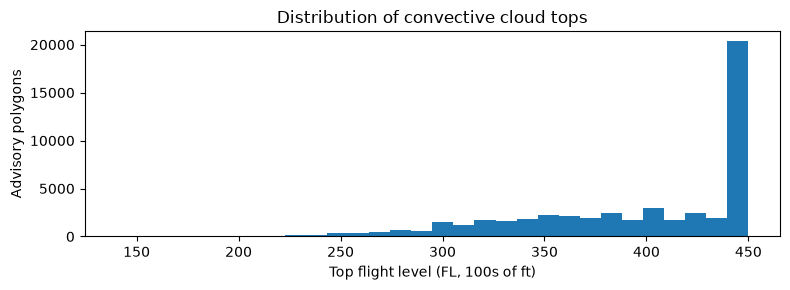

In [11]:
values = advisories['top_fl'].dropna()
ax = values.plot.hist(bins=30, figsize=(8, 3))
ax.set(title='Distribution of convective cloud tops', xlabel='Top flight level (FL, 100s of ft)', ylabel='Advisory polygons')
plt.tight_layout()
plt.show()

## Distribution of active duration

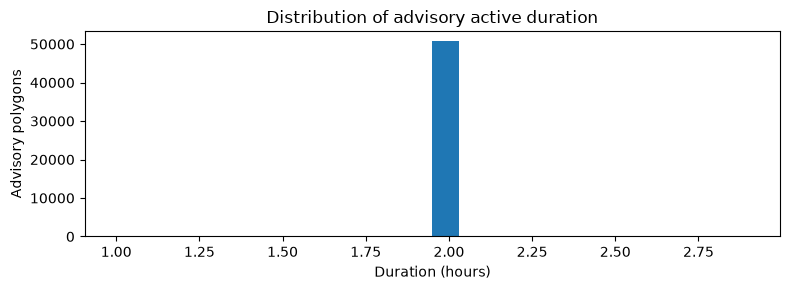

In [12]:
ax = advisories['duration_hours'].plot.hist(bins=24, figsize=(8, 3))
ax.set(title='Distribution of advisory active duration', xlabel='Duration (hours)', ylabel='Advisory polygons')
plt.tight_layout()
plt.show()

## Convective advisories by region

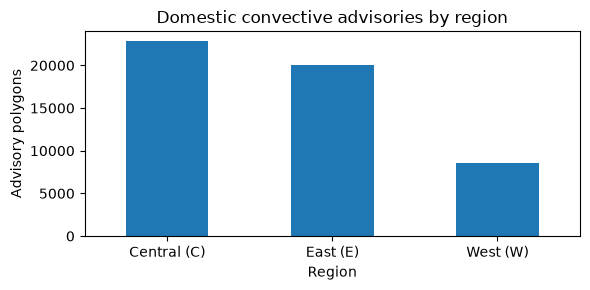

In [13]:
region_labels = {'E': 'East (E)', 'C': 'Central (C)', 'W': 'West (W)'}
counts = advisories['region'].map(region_labels).value_counts()
ax = counts.plot.bar(figsize=(6, 3), rot=0)
ax.set(title='Domestic convective advisories by region', xlabel='Region', ylabel='Advisory polygons')
plt.tight_layout()
plt.show()

## Monthly convective advisory volume

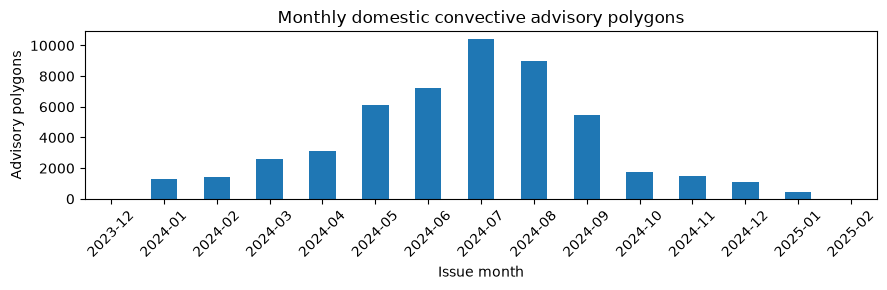

In [14]:
monthly = advisories['issue_utc'].dt.tz_convert(None).dt.to_period('M').value_counts().sort_index()
ax = monthly.plot.bar(figsize=(9, 3), rot=45)
ax.set(title='Monthly domestic convective advisory polygons', xlabel='Issue month', ylabel='Advisory polygons')
plt.tight_layout()
plt.show()

## Spatial footprint of convective advisories

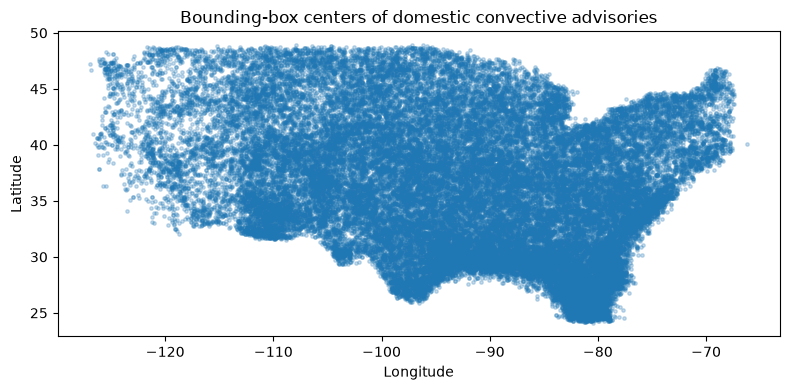

In [15]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.scatter(advisories['center_lon'], advisories['center_lat'], s=6, alpha=0.25)
ax.set(title='Bounding-box centers of domestic convective advisories', xlabel='Longitude', ylabel='Latitude')
plt.tight_layout()
plt.show()

## Data source
Archived convective weather advisory KMLs are retrieved from the [Iowa Environmental Mesonet (IEM) GIS archive](https://mesonet.agron.iastate.edu/request/gis/sigmets.phtml).